# Nickel (Ni) 2D XRD Integration and Rietveld Refinement with `easyXRD`

This notebook documents the complete workflow for processing the raw 2D area-detector diffraction image `Ni.tiff` into a 1D powder diffraction profile and performing full **Rietveld refinement** using **`easyXRD`** and **GSAS-II**.

### Input Files
- **`Ni.tiff`**: Raw 2D area-detector XRD image (Dexela 2923, $3888 \times 3072$ pixels)
- **`_calibration.poni`**: pyFAI detector geometry calibration ($\lambda = 0.1799\ \text{\AA}$, $d \approx 0.5995\ \text{m}$)
- **`_mask.edf`**: Bad-pixel and detector-gap mask
- **`Ni.cif`**: Crystal structure of FCC Nickel ($Fm\bar{3}m$, space group 225)
- **`_instrument_parameters.gpx`**: Pre-calibrated GSAS-II instrument profile parameters


## 1. Imports and Environment Configuration

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fabio
import GSASII.GSASIIscriptable as G2sc
import easyxrd
from easyxrd.core import exrd

plt.rcParams["figure.constrained_layout.use"] = True
easyxrd.show_config()

GSAS-II binaries co-located with GSAS-II: /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII
6 values read from /home/mt/.GSASII/config.ini


easyXRD environment and configurations
Platform            : Linux-7.0.0-42-generic-x86_64-with-glibc2.43
python              : 3.14.10
executable          : /home/mt/mpixi/.pixi/envs/default/bin/python
easyxrd             : 2026.11.2
pyFAI               : 2026.9.0
fabio               : 2026.6.0
numpy               : 2.5.4
scipy               : 1.18.1
pymatgen            : 2026.10.24
GSAS-II             : 2.0.0
GSASII_module       : /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII/GSASIIscriptable.py
verbose             : False
plot_figsize        : (8, 6)
plot_i2d_robust     : True
plot_i1d_ylogscale  : True
plot_i2d_logscale   : True
plot_site_str_x     : 0.4
plot_site_str_y     : 0.8
plot_close          : False
plot_show_wt_fractions: False
plot_show_phase_profiles: True
plot_normalized_residuals: False
i1d_plotter_xlabel  : True
i1d_plotter_return_da: False
i1d_plotter_title_str: 
i1d_plotter_ncol    : 1
i1d_plotter_show_Ybkg_old: False
i1d_plotter_show_phase_p

## 2. Inspect Raw 2D Detector Image and Mask

Image shape: (3888, 3072), dtype: float32, min/max: -145.75 / 6903.61
Mask shape:  (3888, 3072), masked fraction: 0.46%


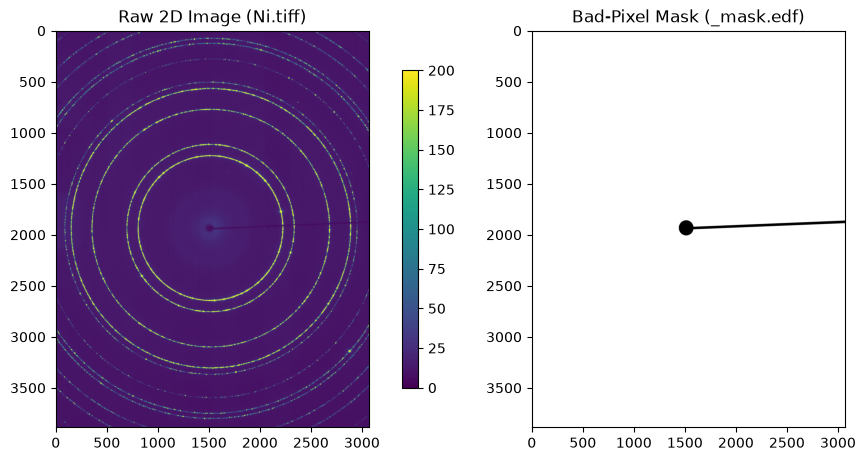

In [2]:
img = fabio.open("Ni.tiff").data
mask = fabio.open("_mask.edf").data
print(f"Image shape: {img.shape}, dtype: {img.dtype}, min/max: {img.min():.2f} / {img.max():.2f}")
print(f"Mask shape:  {mask.shape}, masked fraction: {100 * (mask > 0).mean():.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
im0 = axes[0].imshow(img, vmin=0, vmax=200, cmap="viridis")
axes[0].set_title("Raw 2D Image (Ni.tiff)")
fig.colorbar(im0, ax=axes[0], shrink=0.8)

axes[1].imshow(mask, cmap="gray_r")
axes[1].set_title("Bad-Pixel Mask (_mask.edf)")
plt.show()

## 3. 2D-to-1D Azimuthal Integration (`pyFAI`)

We first integrate over the default radial range to inspect the full $q$ coverage (`0.30` to `10.47` $\text{\AA}^{-1}$).

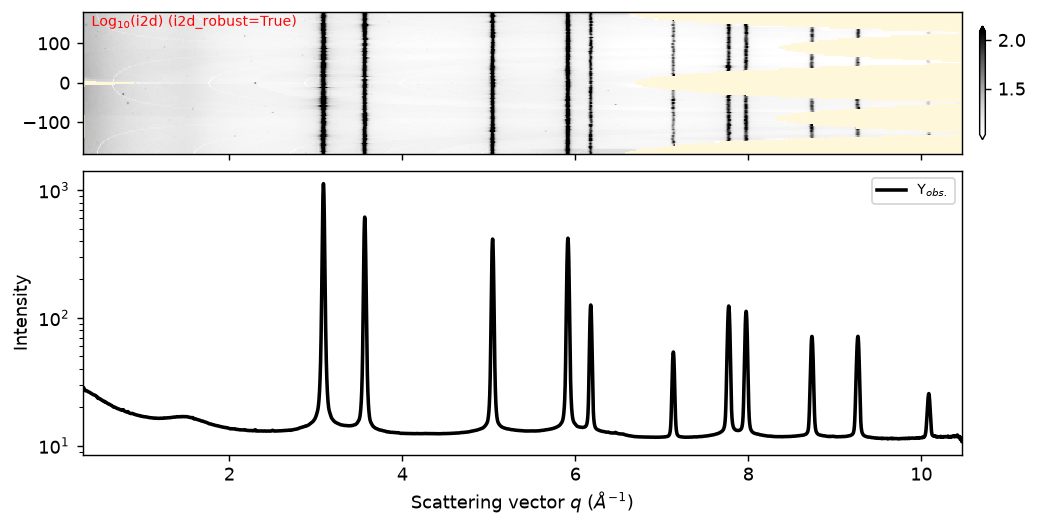

In [3]:
sample_full = exrd()
sample_full.load_xrd_data(
    from_tiff_file="Ni.tiff",
    poni_file="_calibration.poni",
    mask_file="_mask.edf",
    plot=True,
)

From the full-range overview:
- Below $q \approx 2.0\ \text{\AA}^{-1}$, there is a broad background hump (around $q \approx 1.5\ \text{\AA}^{-1}$) and beamstop scattering, with no Ni Bragg peaks.
- Above $q \approx 10.4\ \text{\AA}^{-1}$, the intensity drops slightly at the detector corner boundary.

Restricting `radial_range=[2.0, 10.4]` $\text{\AA}^{-1}$ retains all 11 observed Ni Bragg reflections from `(111)` to `(440)` with a clean, flat background. We also export the integrated 1D profile to `Ni_1D_q.xy`.

Exported 1D profile to Ni_1D_q.xy


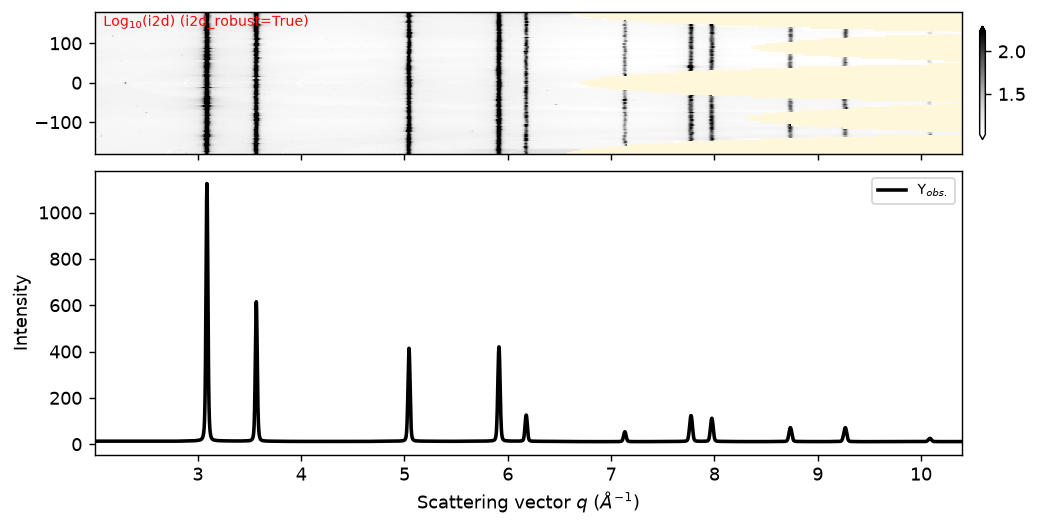

In [4]:
sample = exrd(i1d_ylogscale=False)
sample.load_xrd_data(
    from_tiff_file="Ni.tiff",
    poni_file="_calibration.poni",
    mask_file="_mask.edf",
    radial_range=[2.0, 10.4],
    plot=True,
)
sample.export_i1d_to("Ni_1D_q.xy")
print("Exported 1D profile to Ni_1D_q.xy")

## 4. Phase Matching (`Ni.cif`)

We load `Ni.cif` (cubic $Fm\bar{3}m$, $a = 3.5256\ \text{\AA}$) and verify that all observed Bragg peaks are indexed by FCC Ni.

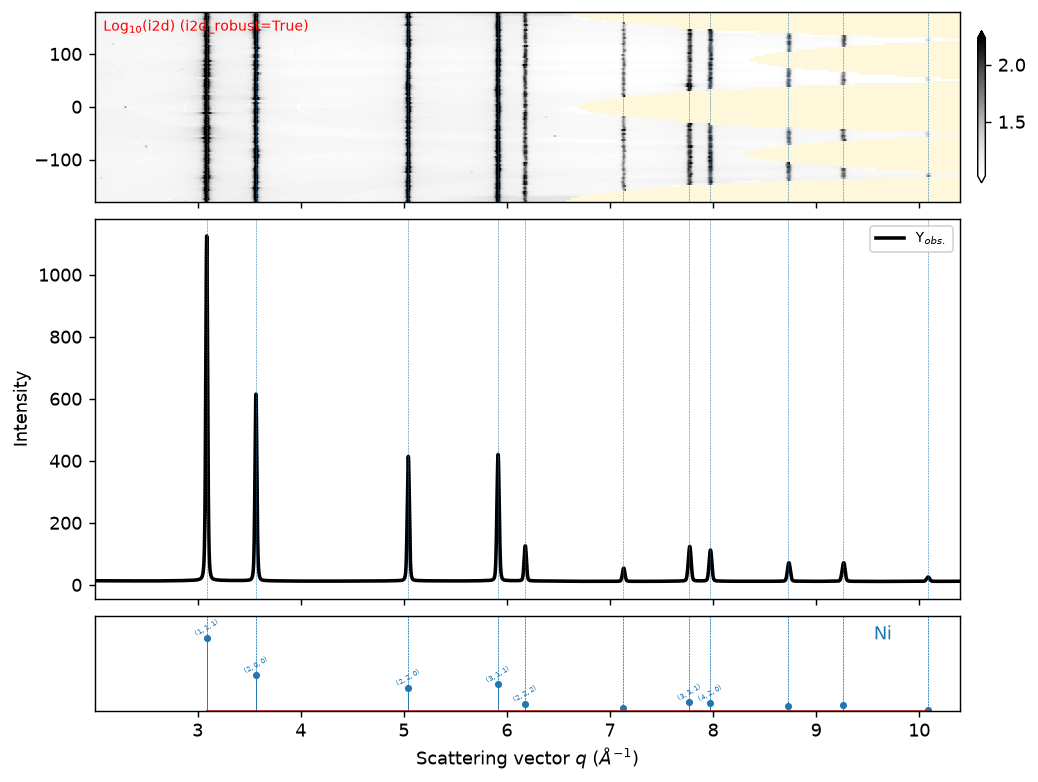

In [5]:
sample.load_phases([{"cif": "Ni.cif", "label": "Ni"}], plot=True)

## 5. Read Instrument Parameters from `_instrument_parameters.gpx`

We inspect the GSAS-II instrument parameters stored in `_instrument_parameters.gpx`. Note that `_instrument_parameters.gpx` contains `Y = -1.0844`, which causes the GSAS-II Lorentzian peak width ($\gamma = X/\cos\theta + Y\tan\theta + Z$) to become negative for $q > 7.45\ \text{\AA}^{-1}$ ($2\theta > 12.2^\circ$) and triggers `easyXRD`'s physicality guard. To preserve the calibrated instrument profile while keeping peak widths physically non-negative across the full `[2.0, 10.4]` $\text{\AA}^{-1}$ range, we transfer all instrument parameters from `_instrument_parameters.gpx` and clamp `instprm_Y=0.0`.

Instrument parameters in _instrument_parameters.gpx:
  Lam       : 0.1799
  Polariz.  : 0.0
  Azimuth   : 0.0
  Zero      : 0.0
  U         : -29.429568076072545
  V         : 13.79133563712429
  W         : 0.8708911222388265
  X         : 0.07517037719725798
  Y         : -1.0844016461422603
  Z         : 0.040769097713890166
  SH/L      : 0.005540666212782422


/home/mt/mpixi/easyXRD/easyxrd/refinement.py:1030: UserWarning: No measurement variance supplied: using unit weights; GoF and uncertainties lack a counting-statistics interpretation
  warnings.warn("No measurement variance supplied: using unit weights; GoF and uncertainties lack a counting-statistics interpretation", UserWarning)


 ✅--1st refinement with LeBail is completed. Rwp/GoF is 26.960/17.918


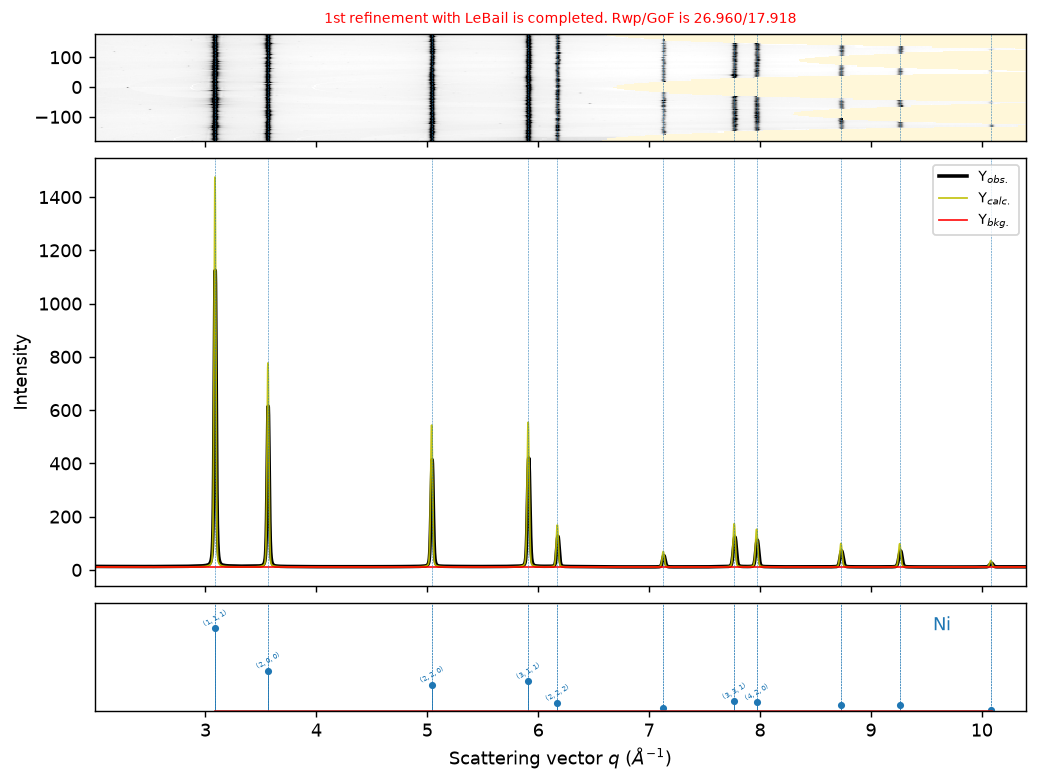

In [6]:
gpx_inst = G2sc.G2Project("_instrument_parameters.gpx")
inst = gpx_inst.histograms()[0]["Instrument Parameters"][0]

print("Instrument parameters in _instrument_parameters.gpx:")
for key in ["Lam", "Polariz.", "Azimuth", "Zero", "U", "V", "W", "X", "Y", "Z", "SH/L"]:
    print(f"  {key:10s}: {inst[key][1]}")

sample.setup_gsas2_refiner(
    plot=True,
    normalize=True,
    instprm_Polariz=float(inst["Polariz."][1]),
    instprm_Azimuth=float(inst["Azimuth"][1]),
    instprm_Zero=float(inst["Zero"][1]),
    instprm_U=float(inst["U"][1]),
    instprm_V=float(inst["V"][1]),
    instprm_W=float(inst["W"][1]),
    instprm_X=float(inst["X"][1]),
    instprm_Y=0.0,
    instprm_Z=float(inst["Z"][1]),
    instprm_SHL=float(inst["SH/L"][1]),
)

## 6. Le Bail Initialization & Full Rietveld Refinement

We first perform a Le Bail pre-refinement (background, unit cell, and isotropic crystallite size broadening) to establish peak positions and widths, then switch to full **Rietveld refinement** (`set_LeBail(to=False)`).

Because the 2D cake (`i2d`) exhibits azimuthal intensity variations indicative of crystallographic texture (preferred orientation), we refine spherical harmonics preferred orientation sequentially (`order = 4, 6, 8`), followed by unit cell, 15-coefficient Chebyshev background, and the Ni isotropic atomic displacement parameter ($U_{\text{iso}}$).

In [7]:
# Stage 1: Le Bail pre-refinement
sample.refine_background(num_coeffs=10, plot=False)
sample.refine_cell_parameters(plot=False)
sample.refine_size_broadening(plot=False)

# Stage 2: Switch to Rietveld refinement
sample.set_LeBail(to=False, refine=True, plot=False)

# Stage 3: Model crystallographic texture via spherical harmonics
for order in [4, 6, 8]:
    sample.refine_preferred_orientation(
        phase_ind=0,
        harmonics_order=order,
        plot=False,
        min_gof_improvement=0.1,
    )

# Stage 4: Final sequential parameter polish
sample.refine_cell_parameters(plot=False)
sample.refine_background(num_coeffs=15, plot=False, min_gof_improvement=0.1)
sample.refine_site_property(phase_ind=0, site_ind=0, refinement_flags="U", plot=False)

 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 22.567/15.007 (was 26.960(-16.29%)/17.918(-16.24%*))


 ✅--Cell parameters are refined. Rwp/GoF is now 10.830/7.198 (was 22.567(-52.01%)/15.007(-52.03%*))


 ✅--Size broadening of all phases are refined. Rwp/GoF is now 7.361/4.893 (was 10.830(-32.03%)/7.198(-32.03%*))
 ✅--After setting LeBail refinement to False, Rwp/GoF is now 17.029/11.318 (was 7.361(131.33%)/4.893(131.31%!))


 ✅--Spherical harmonics preferred orientation (order=4) refined. Rwp/GoF is now 15.336/10.193 (was 17.029(-9.94%)/11.318(-9.94%))


 ✅--Spherical harmonics preferred orientation (order=6) refined. Rwp/GoF is now 10.264/6.823 (was 15.336(-33.07%)/10.193(-33.07%*))


 ✅--Spherical harmonics preferred orientation (order=8) refined. Rwp/GoF is now 8.448/5.615 (was 10.264(-17.70%)/6.823(-17.69%*))


 ✅--Cell parameters are refined. Rwp/GoF is now 7.180/4.772 (was 8.448(-15.00%)/5.615(-15.01%*))


 ✅--Background with 15 coeffs is refined. Rwp/GoF is now 6.211/4.132 (was 7.180(-13.50%)/4.772(-13.43%*))


 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 6.048/4.020 (was 6.211(-2.63%)/4.132(-2.71%))


## 7. Final Fit Visualization, Refinement History, and Exports

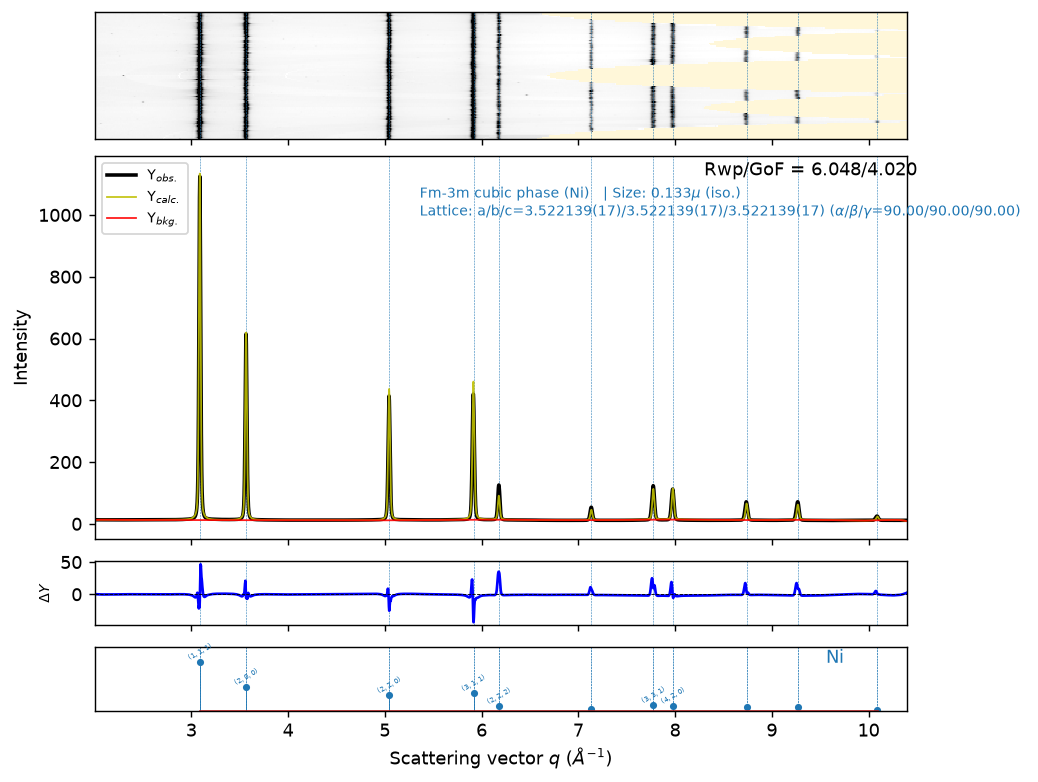

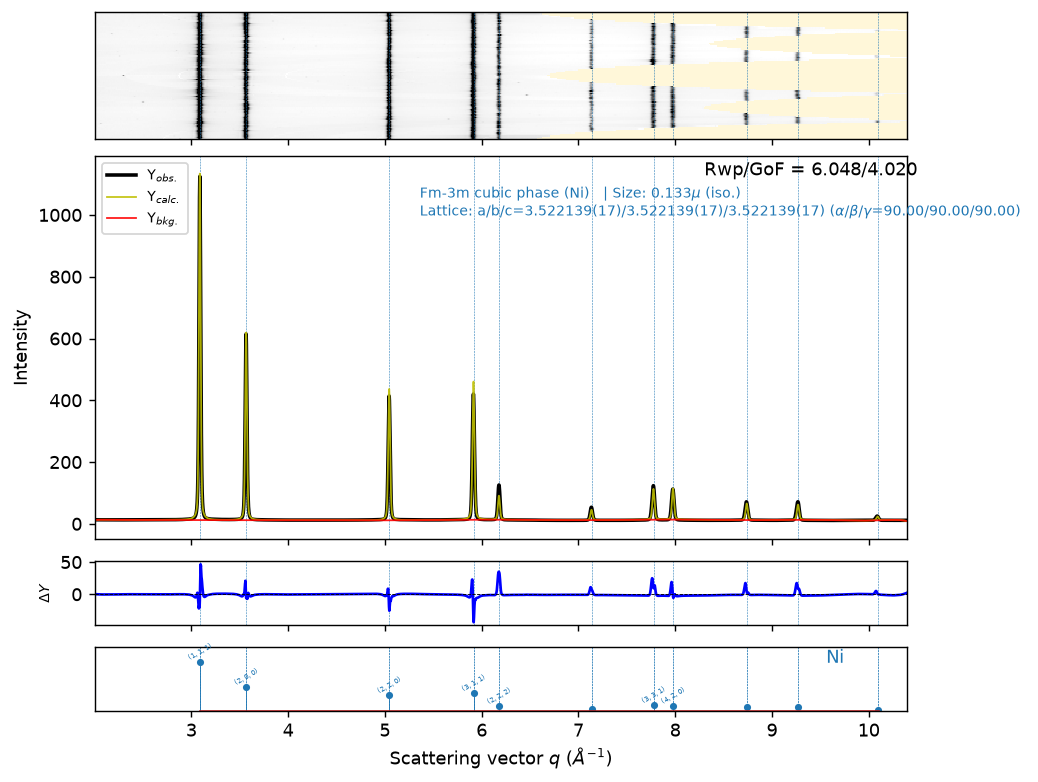

In [8]:
sample.plot(i1d_ylogscale=False, export_fig_as="Ni_Rietveld_plot.pdf")
sample.plot(i1d_ylogscale=False, export_fig_as="Ni_Rietveld_plot.png")

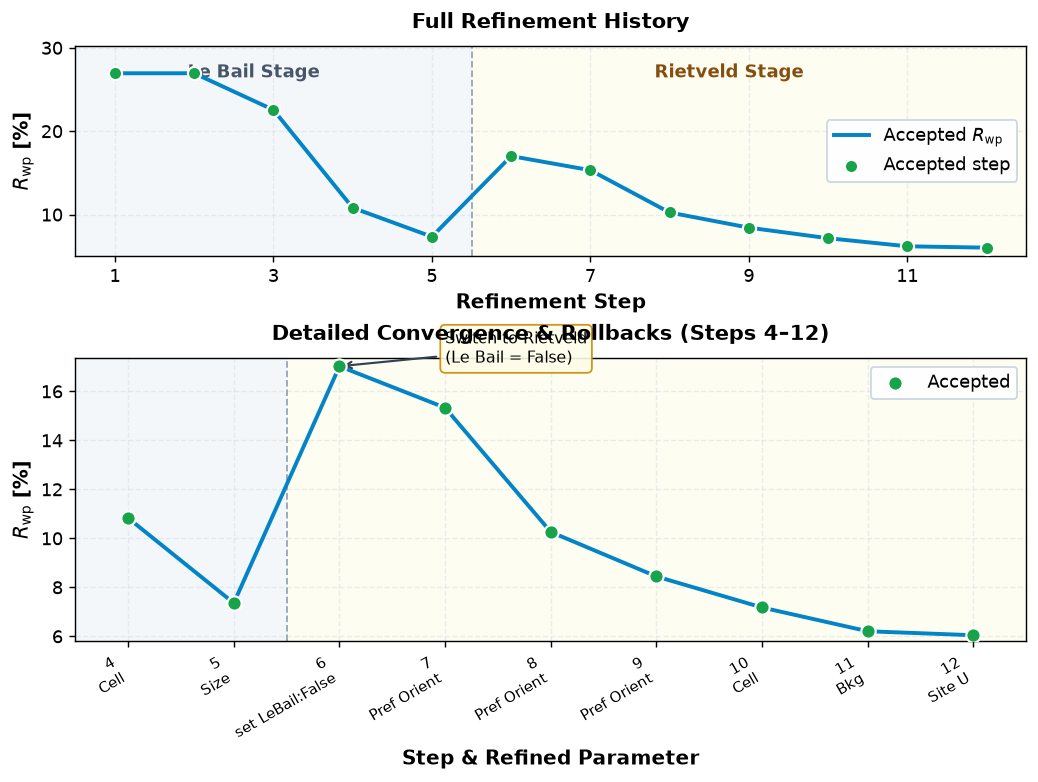

In [9]:
sample.plot_refinement_history()

In [10]:
phase = sample.gpx.phases()[0]
cell = phase.get_cell()
ni_atom = phase.data["Atoms"][0]

print(f"Final Rwp:  {sample.ds.attrs.get('Rwp'):.3f}%")
print(f"Lattice a:  {cell['length_a']:.6f} Å")
print(f"Volume:     {cell['volume']:.6f} Å³")
print(f"Ni Uiso:    {ni_atom[10]:.6f} Å²")

sample.export_gpx_to("Ni_refined.gpx")
sample.export_ds_to("Ni_refined.nc")
print("Saved Ni_refined.gpx and Ni_refined.nc")

Final Rwp:  6.048%
Lattice a:  3.522139 Å
Volume:     43.693759 Å³
Ni Uiso:    0.008558 Å²
Saved Ni_refined.gpx and Ni_refined.nc
